# Jansen-Rit

In [158]:
from tvb.simulator.lab import *
import numpy as np

## Node

In [171]:
####################################################### Parameters ############################################################
# general
# -------
integration_step_size = 0.01 # [ms]
simulation_duration = 1000  # [ms]

# node parameters
# ---------------
A = np.array([3.25]) # Maximum amplitude of EPSP [mV] (default: 3.25)
B = np.array([22.0]) # Maximum amplitude of IPSP [mV] (default: 22.0)

a = np.array([0.1]) # average synaptic time constant for excitatory [ms⁻¹] (default: 0.1)
b = np.array([0.05]) # averge synaptic time constant for inhibitory [ms⁻¹] (default: 0.05)

v0 = np.array([6]) # Firing threshold (PSP) for which 50% firing rate is achieved [mV] (default: 5.52)
nu_max = np.array([0.0025]) # Maximum firing rate [ms⁻¹] (default: 0.0025)
r = np.array([0.56]) # Steepness of sigmoidal transformation [mV⁻¹] (default: 0.56)

J = np.array([135]) # Average number of synapses between populations (default: 135)

p_min = np.array([0.12]) # Minimum input firing rate [s⁻¹] (default: 0.12)
p_max = np.array([0.12]) # Maximum input firing rate [s⁻¹] (default: 0.32)
mu    = np.array([0.12]) # Mean input firing rate [s⁻¹] (default 0.22)

# noise
# -----
phi_n_scaling = (a*A*(p_max-p_min)*0.5)**2 / 2
sigma         = np.zeros(6)
sigma[3]      = phi_n_scaling[0]

n = noise.Additive(nsig=sigma)
###############################################################################################################################

In [172]:
jrm = models.JansenRit(
    A = A,
    B = B,
    a = a,
    b = b,
    v0 = v0,
    nu_max = nu_max,
    r = r,
    J = J,
    p_min = p_min,
    p_max = p_max,
    mu = mu
)

## Connectivity

In [173]:
################################ Parameters #############################
# Connectome
# ----------
weights = np.array([[0,0],[0,0]])   # Connectivity weights (fiber density)
lengths = np.array([[0,0],[0,0]])   # Connectivity lengths (fiber lengths [mm])

# Additional
# ----------
centres = np.array([[0,0,0],[0,0,1]])   # Node positions [mm³]
labels = np.array([0,1]) # Node labels

# Conduction speed
# ----------------
conduction_speed = 3  # conduction speed [mm/ms]

# Couplings
# ---------
c = coupling.SigmoidalJansenRit(a=np.array([0])) # Coupling coefficient (ontop of weight) between nodes
########################################################################

sc = connectivity.Connectivity()

sc.weights = weights
sc.tract_lengths = lengths
sc.centres = centres
sc.region_labels = labels
sc.undirected = True
sc.speed = np.array(conduction_speed)

sc.configure()

N = sc.number_of_regions
print(f"Number of nodes: {N}")

Number of nodes: 2


## Stimulus

In [ ]:
####################### Parameters ##########################
# Input weights
# -------------
stim_weights = np.array([1, 0.0])[:, np.newaxis]

# Pulse
# -----
tau   = 100 # Pulse width or pulse duration [ms] (default: 13)
T     = 5000 # pulse repetition period [ms] (default: 42) 
onset = 200 # Time of the first pulse [ms] (default: 30)
amp   = -5 # amplitude of the pulse [mV] (default: 1)
#############################################################

eqn_t = equations.PulseTrain()
eqn_t.parameters["tau"]   = tau
eqn_t.parameters["T"]     = T
eqn_t.parameters["onset"] = onset
eqn_t.parameters["amp"]   = amp

stimulus = patterns.StimuliRegion(
    temporal = eqn_t,
    connectivity = sc,
    weight = stim_weights,
)

## Simulation

In [191]:
sim = simulator.Simulator(
    model = jrm,
    connectivity = sc,
    coupling = c,
    integrator = integrators.HeunStochastic(dt=integration_step_size, noise=n),
    simulation_length = simulation_duration,
    stimulus = stimulus,
)
sim.configure()

(time, data), = sim.run()

2025-08-14 16:52:34,560 - ERROR - tvb.simulator.simulator - Bad Simulator.integrator.noise.nsig shape: (6, 1, 1)


ValueError: shape mismatch: value array of shape (1,4,1) could not be broadcast to indexing result of shape (2,2,1)

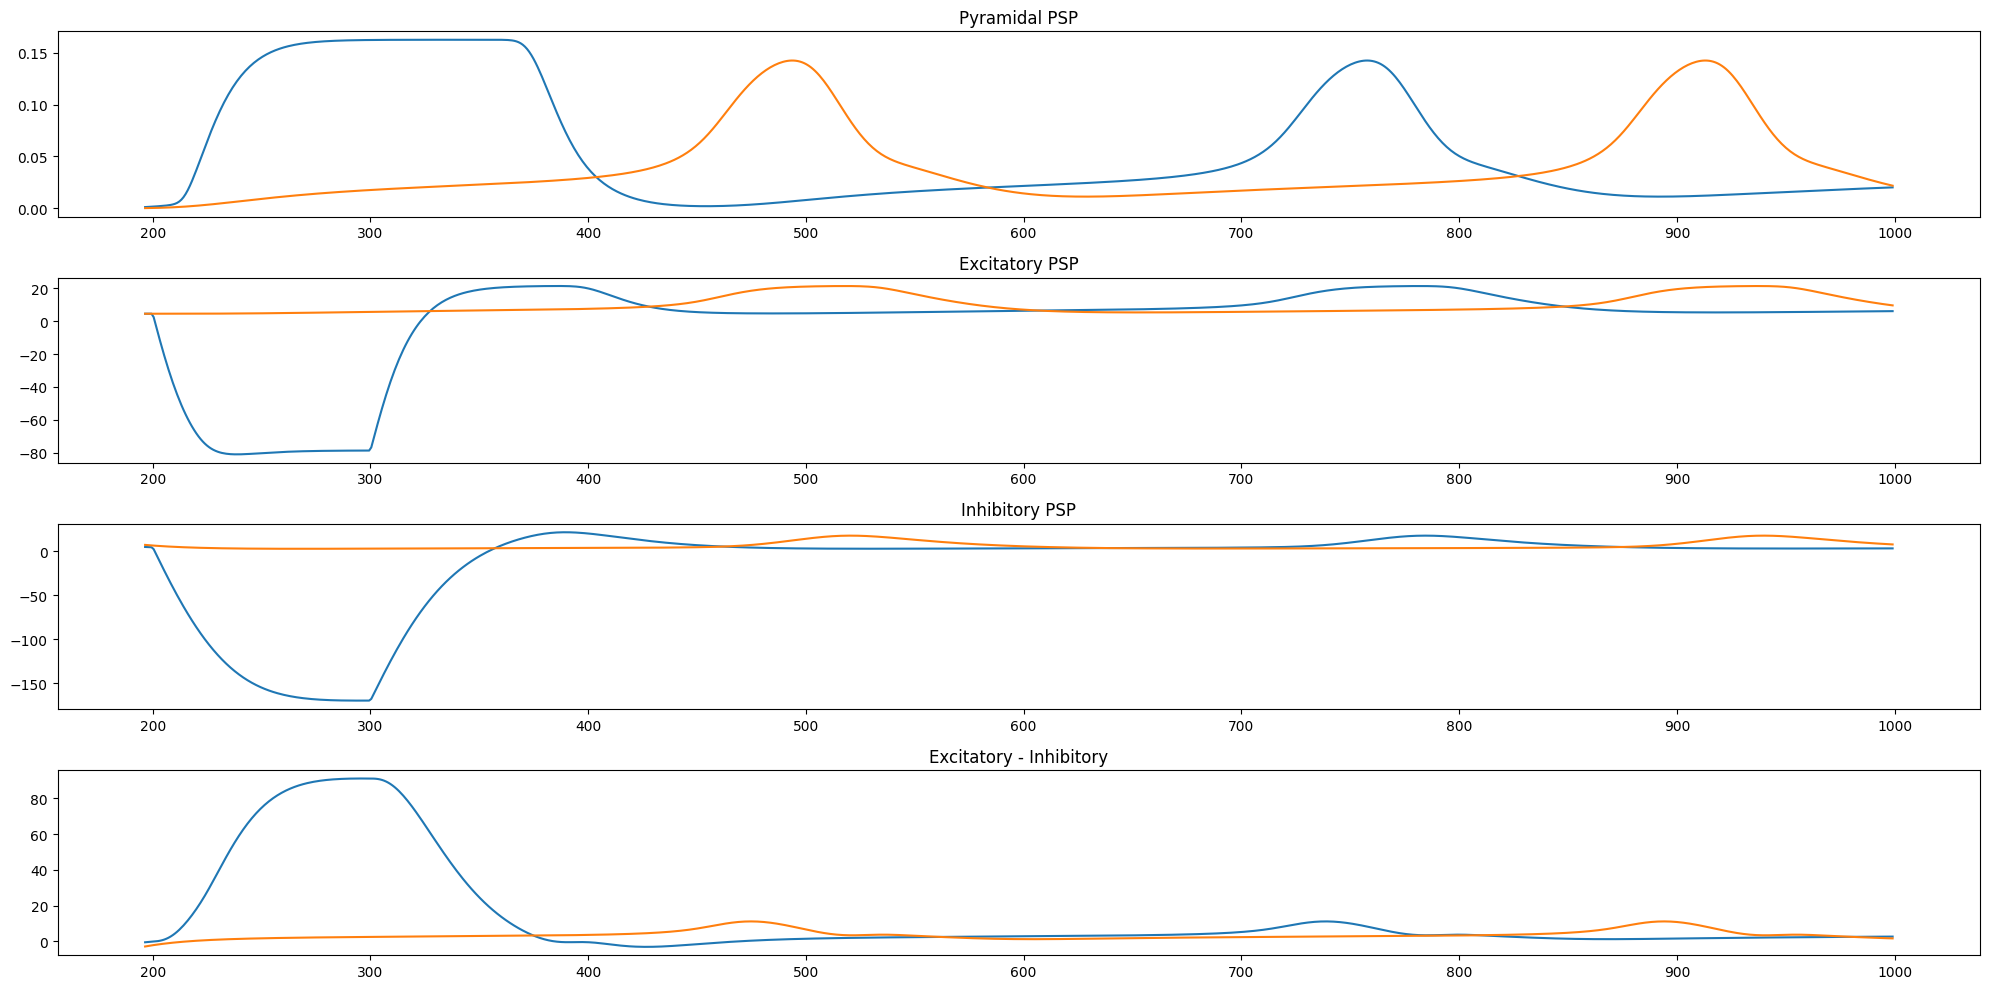

In [192]:
import matplotlib.pyplot as plt

y = data[200:,:,:,:].squeeze()
x = time[200:]

fig, axs = plt.subplots(4,1, figsize=(20,10))

# plot 1
axs[0].plot(x, y[:,0,:])
axs[0].set_title("Pyramidal PSP")

# plot 2
axs[1].plot(x, y[:,1,:])
axs[1].set_title("Excitatory PSP")

# plot 3
axs[2].plot(x, y[:,2,:])
axs[2].set_title("Inhibitory PSP")

# plot 4
axs[3].plot(x, y[:,1,:]-y[:,2,:])
axs[3].set_title("Excitatory - Inhibitory")

plt.tight_layout()
plt.show()

# Zatterberg-Jansen

In [1]:
from tvb.simulator.lab import *
import numpy as np

## Node

<img src="Jansen.png" alt="Does not work" style="max-width:1000px;">

In [30]:
####################################################### Parameters ############################################################
# general
# -------
integration_step_size = 0.01 # [ms]
simulation_duration = 1000  # [ms]

# node parameters
# ---------------
He = np.array([3.25])       # Maximum amplitude of EPSP [mV] (default: 3.25)
Hi = np.array([22.0])       # Maximum aplitude of IPSP [mV] (default: 22.0)
ke = np.array([0.1])        # Average synaptic time constant for excitatory populations [ms⁻¹] (default: 0.1)
ki = np.array([0.05])       # Average synaptic time constant for inhibitory populations [ms⁻¹] (default: 0.05)
e0 = np.array([0.0025])     # Half of the maximum population mean firing rate [ms⁻¹] (default: 0.0025)
rho_2 = np.array([6.0])     # Firing threshold (PSP) for which a 50% firing rate is achieved
rho_1 = np.array([0.56])    # Steepness of the sigmoidal transformation [mV⁻¹]
gamma_1 = np.array([135.0]) # Average number of synapses between populations (pyramidal -> stellate) (default: 135.0)
gamma_2 = np.array([108.0]) # Average number of synapses between populations (stellate -> pyramidal) (default: 108.0)
gamma_3 = np.array([33.75]) # Connectivity constant (pyramidal -> interneurons) (default: 33.75)
gamma_4 = np.array([33.75]) # Connectivity constant (interneurons -> pyramidal) (default: 33.75)
gamma_5 = np.array([15.0])  # Connectivity constant (interneurons -> interneurons) (default: 15.0)
gamma_1T = np.array([0.0])  # Coupling factor from the extrinsic input to the spiny stellate population (default: 1)
gamma_2T = np.array([0.0])  # Coupling factor from the extrinsic input to the pyramidal population (default: 1)
gamma_3T = np.array([0.0])  # Coupling factor from the extrinsic input to the inhibitory population (default: 1)
P = np.array([0])        # Maximum firing rate to the pyramidal population [ms⁻¹] (default: 0.12)
U = np.array([0])        # Maximum firing rate to the stellate population [ms⁻¹] (default: 0.12)
Q = np.array([0])        # Maximum firing rate to the interneurons population [ms⁻¹] (default: 0.12)

###############################################################################################################################

zj = models.ZetterbergJansen(
    He=He, Hi=Hi, ke=ke, ki=ki, 
    e0=e0, rho_2=rho_2, rho_1=rho_1,
    gamma_1=gamma_1, gamma_2=gamma_2, gamma_3=gamma_3, gamma_4=gamma_4, gamma_5=gamma_5, 
    gamma_1T=gamma_1T, gamma_2T=gamma_2T, gamma_3T=gamma_3T,
    P=P, U=U, Q=Q,
)

print(zj.variables_of_interest)

('v6', 'v7', 'v2', 'v3', 'v4', 'v5')


## Connectivity

In [31]:
################################ Parameters #############################
# Connectome
# ----------
weights = np.array([[0,0],[0,0]])   # Connectivity weights (fiber density)
lengths = np.array([[0,0],[0,0]])   # Connectivity lengths (fiber lengths [mm])

# Additional
# ----------
centres = np.array([[0,0,0],[0,0,1]])   # Node positions [mm³]
labels = np.array([0,1]) # Node labels

# Conduction speed
# ----------------
conduction_speed = 3  # conduction speed [mm/ms]

# Couplings
# ---------
c = coupling.SigmoidalJansenRit(a=np.array([0])) # Coupling coefficient (ontop of weight) between nodes
########################################################################

sc = connectivity.Connectivity()

sc.weights = weights
sc.tract_lengths = lengths
sc.centres = centres
sc.region_labels = labels
sc.undirected = True
sc.speed = np.array(conduction_speed)

sc.configure()

N = sc.number_of_regions
print(f"Number of nodes: {N}")

Number of nodes: 2


## Stimulus

In [32]:
####################### Parameters ##########################
# Input weights
# -------------
stim_weights = np.array(
    [1, 0.0])[:, np.newaxis]

# Pulse
# -----
tau   = 10 # Pulse width or pulse duration [ms] (default: 13)
T     = 1000 # pulse repetition period [ms] (default: 42) 
onset = 300 # Time of the first pulse [ms] (default: 30)
amp   = 50 # amplitude of the pulse [mV] (default: 1)
#############################################################

eqn_t = equations.PulseTrain()
eqn_t.parameters["tau"]   = tau
eqn_t.parameters["T"]     = T
eqn_t.parameters["onset"] = onset
eqn_t.parameters["amp"]   = amp

stimulus = patterns.StimuliRegion(
    temporal = eqn_t,
    connectivity = sc,
    weight = stim_weights,
)
time = np.r_[0:simulation_duration:integration_step_size]
stimulus.configure_space()
stimulus.configure_time(time)

Text(0, 0.5, 'Activity')

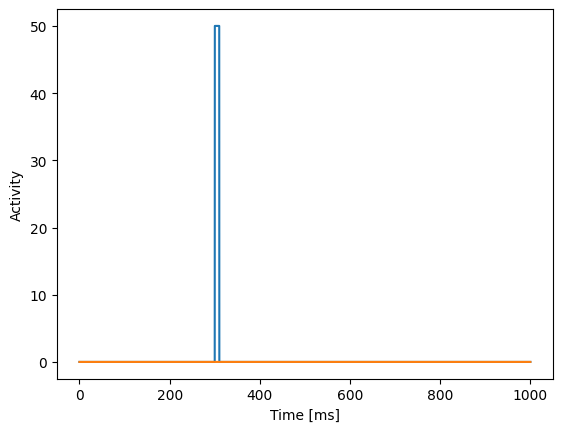

In [33]:
import matplotlib.pyplot as plt

plt.plot(time, stimulus().squeeze().T)
plt.xlabel("Time [ms]")
plt.ylabel("Activity")

## Simulation

In [34]:
sim = simulator.Simulator(
    model = zj,
    connectivity = sc,
    #coupling = c,
    integrator = integrators.HeunStochastic(dt=integration_step_size),
    simulation_length = simulation_duration,
    stimulus = stimulus,
)
sim.configure()

(time, data), = sim.run()

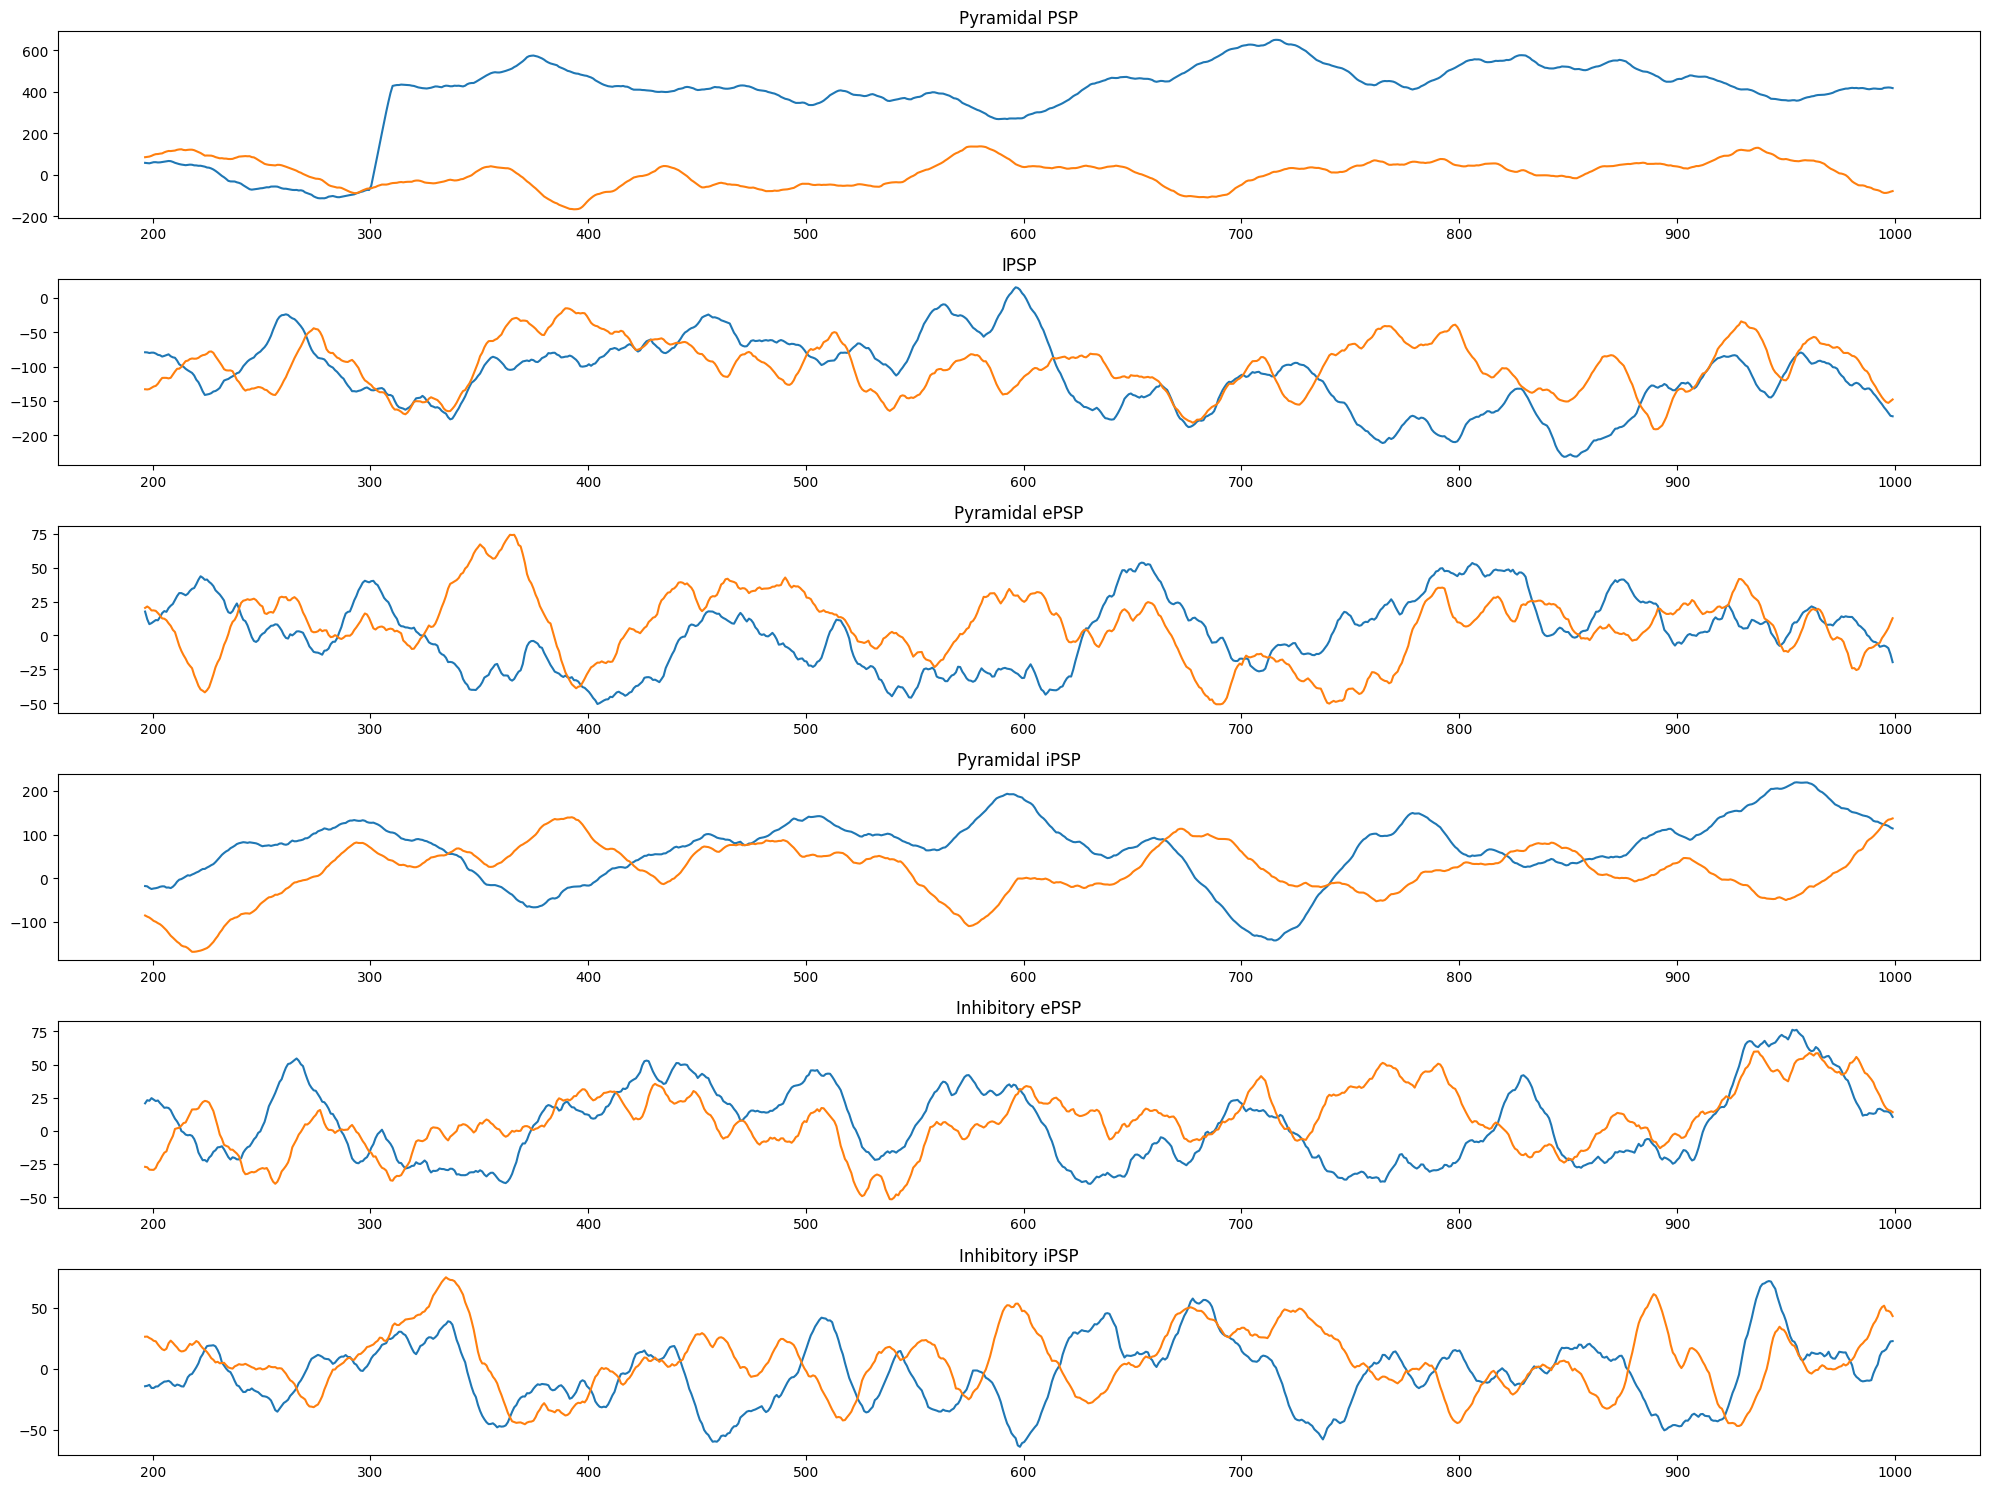

In [35]:
import matplotlib.pyplot as plt

y = data[200:,:,:,:].squeeze()
x = time[200:]

fig, axs = plt.subplots(6,1, figsize=(20,15))

# plot 1
axs[0].plot(x, y[:,0,:])
axs[0].set_title("Pyramidal PSP")

# plot 2
axs[1].plot(x, y[:,1,:])
axs[1].set_title("IPSP")

# plot 3
axs[2].plot(x, y[:,2,:])
axs[2].set_title("Pyramidal ePSP")

# plot 4
axs[3].plot(x, y[:,3,:])
axs[3].set_title("Pyramidal iPSP")

# plot 5
axs[4].plot(x,y[:,4,:])
axs[4].set_title("Inhibitory ePSP")

# plot 6
axs[5].plot(x,y[:,5,:])
axs[5].set_title("Inhibitory iPSP")

plt.tight_layout()
plt.show()

# Bin He

Note:
- All nodes have A=3.25 except one. That one is more apt to spike.
- mean is for the mean input firing rate and std is to define ?noise sigma?

In [36]:
from tvb.simulator.lab import *
import numpy as np

region_id = 1

In [ ]:
############################# Parameters ############################
# Node
# -----
region_id = 1   # Sensitive region
mu = 0.083      # mean firing rate (default: 0.087, 0.08 or 0.083)

# Noise
# -----
std = 1.7       # standard deviation metric ??? (default: 1, 1.7, 1.5)

# Stimulus
# --------
tau   = 10 # Pulse width or pulse duration [ms] (default: 13)
T     = 1000 # pulse repetition period [ms] (default: 42) 
onset = 3000 # Time of the first pulse [ms] (default: 30)
amp   = 0 # amplitude of the pulse [mV] (default: 1)
#####################################################################


conn = connectivity.Connectivity.from_file(source_file="/home/nino/Code/mindmap/tutorials/simulations/connectivity_998.zip")
conn.configure()

# define A value
num_region = conn.number_of_regions
A = np.ones((num_region)) * 3.25
A[region_id] = 3.5


# Node 
# ----
jrm = models.JansenRit(
    A = A,
    mu = np.array([mu]),
    v0 = np.array([6.]),
    p_max = np.array([0.03]),   # (default: 0.15)
    p_min = np.array([0.03]),
)

# Noise
# -----

phi_n_scaling = (jrm.a * 3.25 * (jrm.p_max - jrm.p_min) * 0.5 * std)**2 / 2
sigma = np.zeros(6)
sigma[4] = phi_n_scaling[0]

# Stimulus
# --------
stim_weights = np.zeros(num_region)[:,np.newaxis]
stim_weights[region_id,0] = 1.0

eqn_t = equations.PulseTrain()
eqn_t.parameters["tau"]   = tau
eqn_t.parameters["T"]     = T
eqn_t.parameters["onset"] = onset
eqn_t.parameters["amp"]   = amp

stimulus = patterns.StimuliRegion(
    temporal = eqn_t,
    connectivity = conn,
    weight = stim_weights,
)

# Simulation
# ----------
sim = simulator.Simulator(
    model = jrm,
    connectivity = conn,
    coupling = coupling.SigmoidalJansenRit(a=np.array([1.1])),
    integrator = integrators.HeunStochastic(dt=2**-1, noise=noise.Additive(nsig=sigma)),
    monitors = (monitors.Raw(),),
    stimulus = stimulus,
).configure()

out = sim.run(simulation_length=1e4)
(t, data), = out

2025-08-15 17:59:48,109 - WARNING - tvb.basic.readers - File 'cortical' not found in ZIP.
2025-08-15 17:59:48,110 - WARNING - tvb.basic.readers - File 'hemispheres' not found in ZIP.


In [108]:
# process data
data_ = (data[:,1,:,:] - data[:,2,:,:]).squeeze().astype(np.float32)
data_ = data_[2000:, :]
t_    = t[2000:]

data_ = data_ / np.max(np.abs(data_))

# nodes with biggest spikes
maxis = np.max(data_, axis=0)
indices = np.argsort(maxis)[-10:]

In [96]:
import pyvista as pv

clim = [-np.max(np.abs(data_)), np.max(np.abs(data_))]
p = pv.Plotter()

def create_mesh(time):
    points = pv.PolyData(conn.centres)
    points["activity"] = data_[int(time/2**-1),:]
    p.add_mesh(points, point_size=20,render_points_as_spheres=True, clim=clim)

p.add_slider_widget(create_mesh, [t_[0], t_[-1]], title="time [ms]")
p.add_mesh(pv.PolyData(conn.centres[indices]), point_size=50)
p.show()
    

Widget(value='<iframe src="http://localhost:43025/index.html?ui=P_0x7f87102b90d0_2&reconnect=auto" class="pyvi…

/tmp/ipykernel_160956/4098227452.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


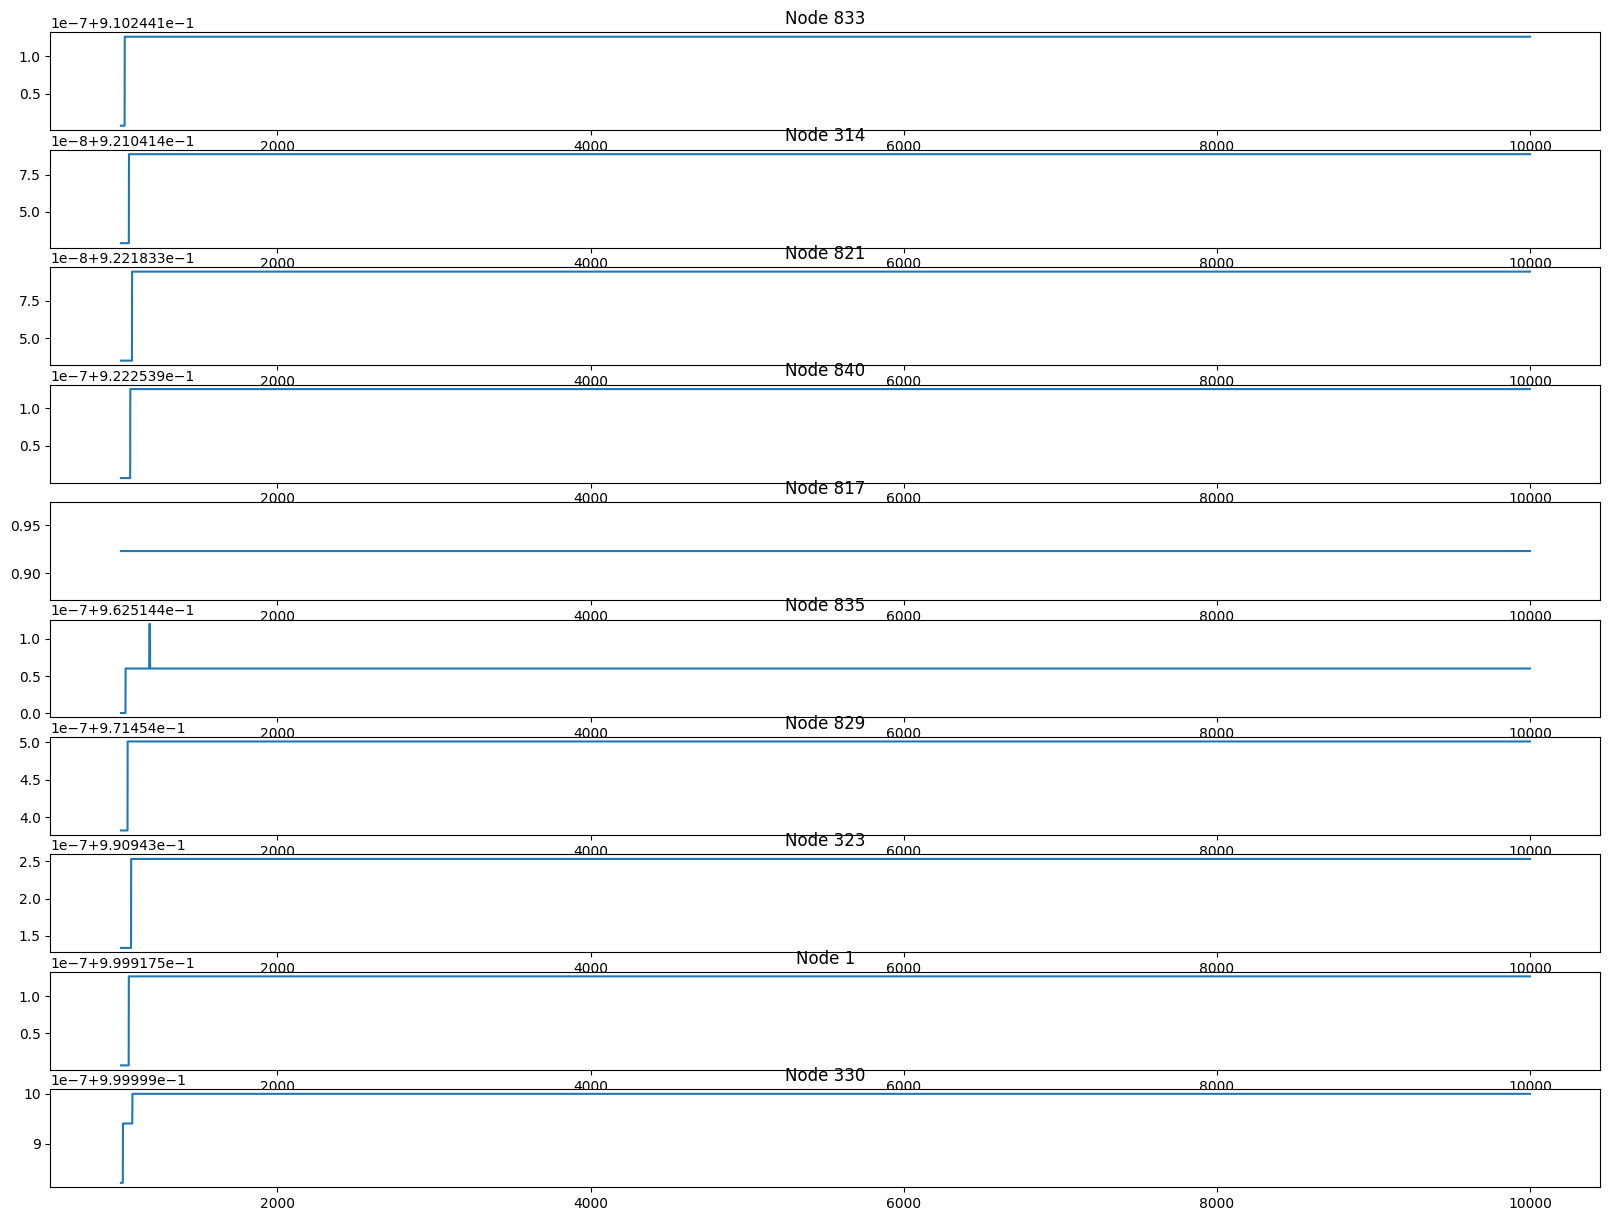

In [109]:
import matplotlib.pyplot as plt 

fig, axs = plt.subplots(nrows=10, ncols=1, figsize=(20,15))

maxis = np.max(data_, axis=0)
indices = np.argsort(maxis)[-10:]

for i,j in enumerate(indices):
    axs[i].plot(t_, data_[:, j])
    axs[i].set_title(f"Node {j}")
fig.show()

# Allemand

In [28]:
from tvb.simulator.lab import *
import numpy as np
from scipy import spatial
from scipy.stats import multivariate_normal

process_id = 10

############################## Parameters #######################################
## Simulation parameters
integration_step_size = 1.0  # ms - time-step-size to be used in the differential equation integration scheme.
simulation_duration = 11000  # ms - duration for which the models should be evolved.
initial_transient = 1000  # ms - transient to be removed from data.

## Model parameters
# network parameters
nx = 30  # number of regions along x-dimension
ny = 30  # number of regions along y-dimension
x_extent = 140  # mm, extent of x-dimension
y_extent = 140  # mm, extent of y-dimension

coupling_strength = np.array([0.1])  # global scaling of all connections
conduction_speed = 3.0  # mm/ms conduction speed between nodes
connection_strength_scaling = 10  # mm - scaling factor for distance-dependent connection strength
connection_probability_scale = 17  # scale parameter for distance-dependent connection probability

instrength_gradient_offset = 4.0  # offset of in-strength gradient field.
instrength_gradient_scaling = 1  # scale the min-max normalized gradient
sink_pos = np.array([40, 40])  # mm - sink position (gaussian)
source_pos = np.array([100, 100])  # mm - source position (gaussian)
singularity_width = 300  # mm^2 - width of sink and source (normal variance)

# kuramoto parameters
intrinsic_frequency_mean = 10.  # Hz - Kuramoto oscillator intrinsic frequency mean
intrinsic_frequency_standard_deviation = 0.0  # Hz - Kuramoto oscillator intrinsic frequency standard deviation
##################################################################################

def exp_kernel(distance, sigma):
    f = 1/(2*sigma) * np.exp(-distance/sigma)
    return f

initial_transient_samples = int(initial_transient/integration_step_size)

# Prepare mesh
# ------------
y = np.linspace(0, y_extent, ny)
x = np.linspace(0, x_extent, nx)
pos = np.array(np.meshgrid(x,y)).T.reshape(-1,2)

# prepare mesh
v = np.c_[pos, np.zeros(len(pos))]
f = spatial.Delaunay(pos).simplices

# Create Network
# --------------
sc = connectivity.Connectivity()
sc.centres = pos

# Create distance-dependent connectivity
distance_matrix = spatial.distance.cdist(pos, pos)
np.fill_diagonal(distance_matrix, np.inf)

A = exp_kernel(distance_matrix, connection_strength_scaling)

N = nx*ny
connection_mask = distance_matrix <= abs(np.random.exponential(scale=connection_probability_scale, size=(N,N)))

A[connection_mask==0] = 0
A /= A.sum(axis=0)

# Create spatial in-strength gradient
sink = multivariate_normal(sink_pos, cov=singularity_width).pdf(pos)
source = multivariate_normal(source_pos, cov=singularity_width).pdf(pos)

gradient = (sink - source)  # combine gaussians to create gradient
gradient = (gradient - gradient.min()) * 2 / (gradient.max() - gradient.min()) -1
instrength_gradient_field = instrength_gradient_scaling * gradient + instrength_gradient_offset

# Create connection strengh distribution based on in-strength gradient field
sc.weights = (A * instrength_gradient_field).T
assert np.all(sc.weights >= 0)

# configure structural connectivtiy of network
sc.tract_lengths = distance_matrix.T 
sc.speed = np.array(conduction_speed)
sc.create_region_labels(mode="alphabetic")
sc.configure()


# Kuramoto model
# --------------
model = models.Kuramoto()

# specify gloabal coupling
global_coupling = coupling.Kuramoto(a=coupling_strength)

# compute intrinsic frequency distribution
intrinsic_frequency_distribution = intrinsic_frequency_standard_deviation * np.random.randn(N) + intrinsic_frequency_mean

# convert intrinsic frequency to intrinsic angular frequency, this has to be radians/ms for TVB
omega = 2*np.pi*intrinsic_frequency_distribution*1e-3
model.omega = omega

# Simulation
# ---------
sim = simulator.Simulator(
    model = model,
    connectivity = sc,
    coupling = global_coupling,
    conduction_speed = conduction_speed,
    integrator = integrators.RungeKutta4thOrderDeterministic(dt=integration_step_size),
    simulation_length = simulation_duration,
    monitors = (monitors.Raw(),)
)
sim.configure()

2025-08-15 14:55:07,683 - WARNING - tvb.simulator.simulator - There may be insufficient memory for this simulation.


/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/tvb/datatypes/connectivity.py:321: RuntimeWarning: invalid value encountered in cast
  self.idelays = numpy.rint(self.delays / dt).astype(numpy.int32)


In [29]:
(time, raw_data), = sim.run()
phase = np.squeeze(raw_data)

2025-08-15 14:55:56,899 - WARNING - tvb.simulator.integrators - random_state supplied for non-stochastic integration


In [37]:
import pyvista as pv
import mindmap as mm

data = np.cos(phase)

# cut
clim = [-np.max(np.abs(data)), np.max(np.abs(data))]
p = pv.Plotter()

def create_mesh(time):
    graph = mm.utils.surf_to_polydata(v, f)
    graph["activity"] = data[int(time/integration_step_size),:]
    p.add_mesh(graph, point_size=10, clim=clim)

p.add_slider_widget(create_mesh, [time[0], time[-1]], title="time [ms]")
p.show()
    

Widget(value='<iframe src="http://localhost:35235/index.html?ui=P_0x7e8159103b50_3&reconnect=auto" class="pyvi…

/tmp/ipykernel_154212/144562105.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


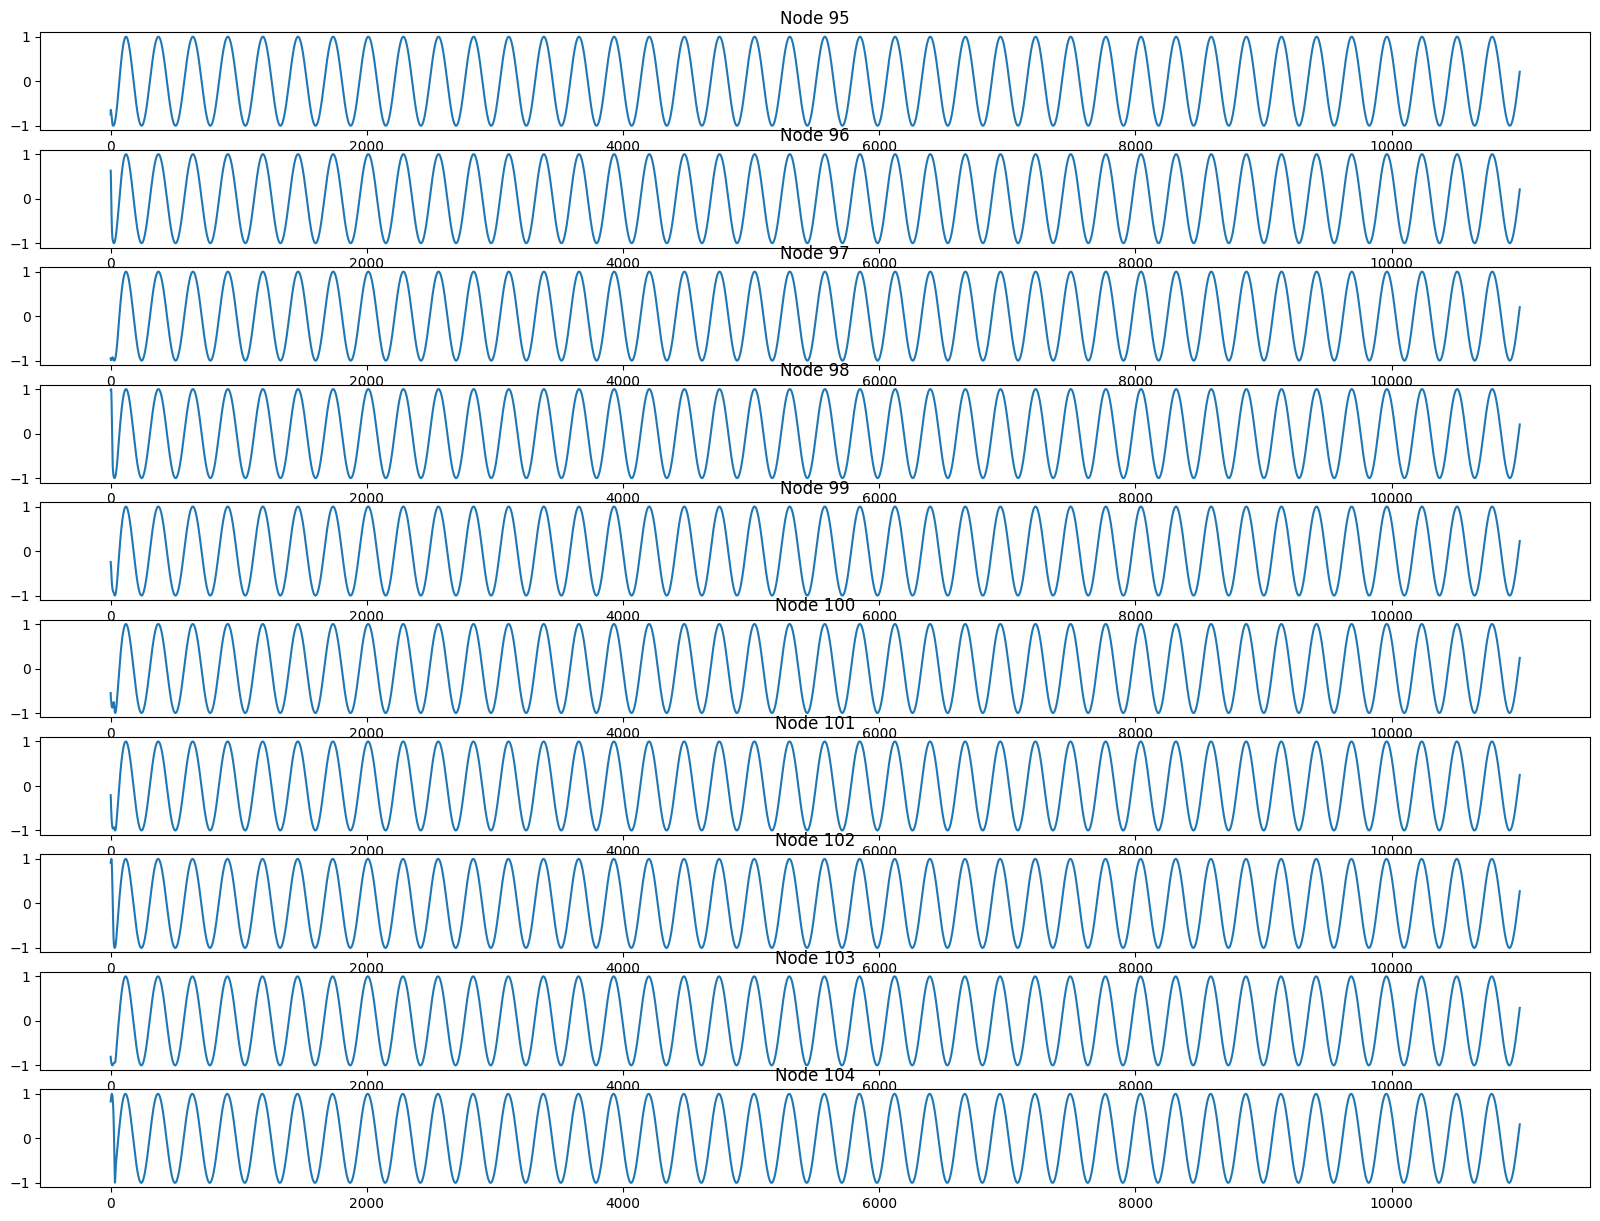

In [38]:
import matplotlib.pyplot as plt 

fig, axs = plt.subplots(nrows=10, ncols=1, figsize=(20,15))

id = 100
id_range = [id-5, id+5]

for i in range(id_range[0], id_range[1]):
    axs[i-id+5].plot(time, data[:, i])
    axs[i-id+5].set_title(f"Node {i}")
fig.show()

# Surface based

## Make new connectome$

In [45]:
import mindmap as mm 
import mne
from tvb.simulator.lab import *

################# Parameters ####################
fconfig = "../../papers/simf/configuration.yml"
sub     = 1
#################################################

# configuration
reader = mm.io.dataset_reader(fconfig)
data   = reader(sub, "ctx", "cras") 

# directories
fs_dir = reader.config["FS_DIR"]
mm_dir = reader.config["MM_DIR"]

########## Parameters ###########
# source space 
spacing = 4

# other options
n_jobs = 10
#################################


# source space
sources = mne.setup_source_space(
    subject=data["sub"],
    spacing=spacing,
    surface="white",
    add_dist=True,      # geodesic distances between sources
    subjects_dir=fs_dir,
    n_jobs=n_jobs,
    verbose="warning",
)

print("\033[92mSUMMARY\033[0m")
for src in sources:
    print(f"Source space id: {src['id']}")
    print(f"Type: {src['type']}")
    print(f"Number of sources: {src['nuse']}\n")

DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- cras
- ctx
Missing objects:
SUMMARY
Source space id: 101 (FIFFV_MNE_SURF_LEFT_HEMI)
Type: surf
Number of sources: 7379

Source space id: 102 (FIFFV_MNE_SURF_RIGHT_HEMI)
Type: surf
Number of sources: 7084



In [49]:
# select 1 hemisphere and generate local connectivity
# ---------------------------------------------------

# source position
labels = sources[0]["vertno"]
centres = sources[0]["rr"][labels]

# distance matrix
dist = sources[0]["dist"][sources[0]["vertno"]][:,sources[0]["vertno"]] * 1000
dist[dist>60] = np.inf      # set 0 weight to far source
dist.setdiag(np.inf)        # avoids self loop

# create connectivity using kernel
def make_kernel(eta, mu1, var1, mu2, var2):
    kernel = lambda x: eta * (mu1*np.exp(-var1*x*x) + mu2*np.exp(-var2*x*x))
    return kernel

kernel = make_kernel(2,1,0.005, -0.5, 0.001)
weights = kernel(dist.todense())

# generate tract length matrix
tract_lengths = dist.todense()
tract_lengths[tract_lengths == np.inf] = 0

# put in a tvb object
conn = connectivity.Connectivity()
conn.centres = centres
conn.region_labels = labels
conn.weights = weights
conn.tract_lengths = tract_lengths

conn.configure()

In [ ]:
############################# Parameters ############################
# Node
# -----
region_id = 1   # Sensitive region
mu = 0.083      # mean firing rate (default: 0.087, 0.08 or 0.083)

# Noise
# -----
std = 1.7       # standard deviation metric ??? (default: 1, 1.7, 1.5)

# Stimulus
# --------
tau   = 10 # Pulse width or pulse duration [ms] (default: 13)
T     = 1000 # pulse repetition period [ms] (default: 42) 
onset = 3000 # Time of the first pulse [ms] (default: 30)
amp   = 0 # amplitude of the pulse [mV] (default: 1)
#####################################################################

# define A value
num_region = conn.number_of_regions
A = np.ones((num_region)) * 3.25
#A[region_id] = 3.5


# Node 
# ----
jrm = models.JansenRit(
    A = A,
    mu = np.array([mu]),
    v0 = np.array([6.]),
    p_max = np.array([0.03]),   # (default: 0.15)
    p_min = np.array([0.03]),
)

# Noise
# -----

phi_n_scaling = (jrm.a * 3.25 * (jrm.p_max - jrm.p_min) * 0.5 * std)**2 / 2
sigma = np.zeros(6)
sigma[4] = phi_n_scaling[0]

# Stimulus
# --------
stim_weights = np.zeros(num_region)[:,np.newaxis]
stim_weights[region_id,0] = 1.0

eqn_t = equations.PulseTrain()
eqn_t.parameters["tau"]   = tau
eqn_t.parameters["T"]     = T
eqn_t.parameters["onset"] = onset
eqn_t.parameters["amp"]   = amp

stimulus = patterns.StimuliRegion(
    temporal = eqn_t,
    connectivity = conn,
    weight = stim_weights,
)

# Simulation
# ----------
sim = simulator.Simulator(
    model = jrm,
    connectivity = conn,
    coupling = coupling.SigmoidalJansenRit(a=np.array([1.1])),
    integrator = integrators.HeunStochastic(dt=2**-1, noise=noise.Additive(nsig=sigma)),
    monitors = (monitors.Raw(),),
    stimulus = stimulus,
).configure()

out = sim.run(simulation_length=1e4)
(t, data), = out

/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/numba/np/ufunc/gufunc.py:261: RuntimeWarning: overflow encountered in _numba_dfun_jr
  return self.ufunc(*args, **kwargs)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/tvb/simulator/coupling.py:372: RuntimeWarning: overflow encountered in exp
  (self.cmax - self.cmin) / (1.0 + numpy.exp(self.r * (self.midpoint - (x_j[:, 0] - x_j[:, 1]))))


In [ ]:
# process data
data_ = (data[:,1,:,:] - data[:,2,:,:]).squeeze().astype(np.float32)
data_ = data_[2000:, :]
t_    = t[2000:]

data_ = data_ / np.max(np.abs(data_))

# nodes with biggest spikes
maxis = np.max(data_, axis=0)
indices = np.argsort(maxis)[-10:]

In [ ]:
import pyvista as pv

clim = [-np.max(np.abs(data_)), np.max(np.abs(data_))]
p = pv.Plotter()

def create_mesh(time):
    points = pv.PolyData(conn.centres)
    points["activity"] = data_[int(time/2**-1),:]
    p.add_mesh(points, point_size=20,render_points_as_spheres=True, clim=clim)

p.add_slider_widget(create_mesh, [t_[0], t_[-1]], title="time [ms]")
p.add_mesh(pv.PolyData(conn.centres[indices]), point_size=50)
p.show()

In [ ]:
import matplotlib.pyplot as plt 

fig, axs = plt.subplots(nrows=10, ncols=1, figsize=(20,15))

maxis = np.max(data_, axis=0)
indices = np.argsort(maxis)[-10:]

for i,j in enumerate(indices):
    axs[i].plot(t_, data_[:, j])
    axs[i].set_title(f"Node {j}")
fig.show()

# Little model

In [106]:
import numpy as np
import pyvista as pv
from scipy.spatial.distance import pdist, squareform
import matplotlib.pyplot as plt
from tvb.simulator.lab import *


def generate_uniform_sphere_points(n_points: int) -> np.ndarray:
    """
    Generates n_points uniformly distributed on the surface of a unit sphere.

    Args:
        n_points (int): The number of points to generate.

    Returns:
        np.ndarray: An array of shape (n_points, 3) where each row is a 
                    (x, y, z) coordinate of a point on the unit sphere.
    """
    # Generate n_points uniform random numbers for the polar angle (phi)
    # in the range [0, 2*pi).
    phi = 2 * np.pi * np.random.rand(n_points)

    # Generate n_points uniform random numbers for the polar angle (theta)
    # The cosine of theta is uniformly distributed in the range [-1, 1].
    # This is a key step to ensure a uniform distribution.
    cos_theta = 2 * np.random.rand(n_points) - 1
    
    # Calculate the sine of theta
    sin_theta = np.sqrt(1 - cos_theta**2)

    # Convert spherical coordinates to Cartesian coordinates
    x = sin_theta * np.cos(phi)
    y = sin_theta * np.sin(phi)
    z = cos_theta

    # Stack the coordinates into a single array
    points = np.stack([x, y, z], axis=1)

    return points


def euclidean_distance_matrix(points: np.ndarray) -> np.ndarray:
    """
    Measures the Euclidean distance between all pairs of points.

    Args:
        points (np.ndarray): An array of shape (n_points, n_dimensions).

    Returns:
        np.ndarray: A symmetric distance matrix of shape (n_points, n_points).
                    The element at (i, j) is the Euclidean distance between
                    point i and point j.
    """
    # Use pdist to compute the condensed distance vector
    condensed_distances = pdist(points, 'euclidean')

    # Use squareform to convert the condensed vector to a full matrix
    distance_matrix = squareform(condensed_distances)

    return distance_matrix

def make_kernel(eta, mu1, var1, mu2, var2):
    kernel = lambda x: eta * (mu1*np.exp(-var1*x*x) + mu2*np.exp(-var2*x*x))
    return kernel

In [130]:
def plot_graph(points, adjacency):
    """
    Parameters
    ----------
    points: np.array (N,3) 
    lines: np.array (N,2)
    """

    P = pv.PolyData(points)
    A1 = adjacency > 0
    A2 = adjacency < 0

    lines1 = []
    lines2 = []
    for i in range(len(A1)):
        for j in range(i, len(A1)):
            if A1[i,j]:
                lines1 += [points[i], points[j]]
            if A2[i,j]:
                lines2 += [points[i], points[j]]
    lines1 = np.array(lines1)
    lines2 = np.array(lines2)

    p = pv.Plotter()
    p.add_mesh(P)
    if len(lines1) > 0:
        p.add_lines(lines1, color="green", width=0.05)
    if len(lines2) > 0:
        p.add_lines(lines2, color="red", width=0.01)

    return p

def process_data(time, data, range_):
    # process data
    data_ = (data[:,1,:,:] - data[:,2,:,:]).squeeze().astype(np.float32)
    data_ = data_[range_[0]:range_[1], :]
    time_ = time[range_[0]:range_[1]]

    data_ = data_ / np.max(np.abs(data_))

    return time_, data_

def plot_graph_activity(conn, time, data, range_ = [2000, -1], show_max=False):

    time, data = process_data(time, data, range_ = range_)
    clim = [-np.max(np.abs(data)), np.max(np.abs(data))]

    p = pv.Plotter()

    def create_mesh(t):
        points = pv.PolyData(conn.centres)
        points["activity"] = data[int((t-time[0])/2**-1),:]
        p.add_mesh(points, point_size=10,render_points_as_spheres=True, clim=clim)

    p.add_slider_widget(create_mesh, [time[0], time[-1]], title="time [ms]")

    if show_max:
        # nodes with biggest spikes
        maxis = np.max(data, axis=0)
        indices = np.argsort(maxis)[-1]

        p.add_mesh(pv.PolyData(conn.centres[indices]), point_size=20)
        
    p.show()

def plot_activity(time, data, node=None, start_idx=2000):

    fig, axs = plt.subplots(nrows=10, ncols=1, figsize=(20,15))

    time, data = process_data(time, data, range_=[start_idx, -1])
    
    if node is None:
        maxis = np.max(data, axis=0)
        indices = np.argsort(maxis)[-10:]
    else:
        indices = np.arange(node-5, node+5)

    for i,j in enumerate(indices):
        axs[i].plot(time, data[:, j])
        axs[i].set_title(f"Node {j}")
    fig.show()

## Figure out the rigth kernel
Reminder: max distance = 2

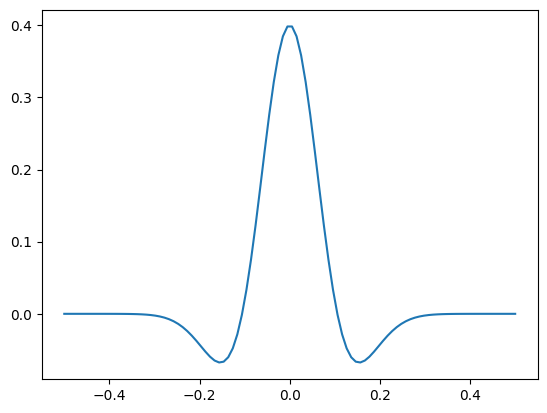

In [103]:
kernel = make_kernel(2, 1, 90, -0.8, 70)

x = np.linspace(-0.5, 0.5, 100)
y = kernel(x)

import matplotlib.pyplot as plt 

plt.plot(x,y)
plt.show()

## Make graph

In [105]:
# points
sphere = generate_uniform_sphere_points(1000)

# distances
dist = euclidean_distance_matrix(sphere)
dist[dist > 0.25] = np.inf
np.fill_diagonal(dist, np.inf)

# weights
kernel = make_kernelkernel = make_kernel(2,1,90, -0.8, 70)
weights = kernel(dist)

# tract lengths
dist[dist == np.inf] = 0

plot_graph(sphere, weights).show()

Widget(value='<iframe src="http://localhost:40815/index.html?ui=P_0x78d7bf635f90_24&reconnect=auto" class="pyv…

## Make simulation

In [123]:
############################# Parameters ############################
# Node
# -----
region_id = 1   # Sensitive region
mu = 0.083      # mean firing rate (default: 0.087, 0.08 or 0.083)

# Noise
# -----
std = 1.7       # standard deviation metric ??? (default: 1, 1.7, 1.5)

# Stimulus
# --------
tau   = 10 # Pulse width or pulse duration [ms] (default: 13)
T     = 1000 # pulse repetition period [ms] (default: 42) 
onset = 3000 # Time of the first pulse [ms] (default: 30)
amp   = 0 # amplitude of the pulse [mV] (default: 1)
#####################################################################

# connectome
conn = connectivity.Connectivity()
conn.weights = np.abs(weights) 
conn.tract_lengths = dist 
conn.centres = sphere 
conn.region_labels = np.arange(len(sphere))
conn.configure()

# define A value
num_region = conn.number_of_regions
A = np.ones((num_region)) * 3.25
#A[region_id] = 3.5


# Node 
# ----
jrm = models.JansenRit(
    A = A,
    mu = np.array([mu]),
    v0 = np.array([6.]),
    p_max = np.array([0.15]),   # (default: 0.15)
    p_min = np.array([0.03]),
)

# Noise
# -----
phi_n_scaling = (jrm.a * 3.25 * (jrm.p_max - jrm.p_min) * 0.5 * std)**2 / 2
sigma = np.zeros(6)
sigma[4] = phi_n_scaling[0]

# Stimulus
# --------
stim_weights = np.zeros(num_region)[:,np.newaxis]
stim_weights[region_id,0] = 1.0

eqn_t = equations.PulseTrain()
eqn_t.parameters["tau"]   = tau
eqn_t.parameters["T"]     = T
eqn_t.parameters["onset"] = onset
eqn_t.parameters["amp"]   = amp

stimulus = patterns.StimuliRegion(
    temporal = eqn_t,
    connectivity = conn,
    weight = stim_weights,
)

# Simulation
# ----------
sim = simulator.Simulator(
    model = jrm,
    connectivity = conn,
    coupling = coupling.SigmoidalJansenRit(a=np.array([100])),
    integrator = integrators.HeunStochastic(dt=2**-1, noise=noise.Additive(nsig=sigma)),
    monitors = (monitors.Raw(),),
    stimulus = stimulus,
).configure()

out = sim.run(simulation_length=1e4)
(t, data), = out

/tmp/ipykernel_209706/2452298041.py:81: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


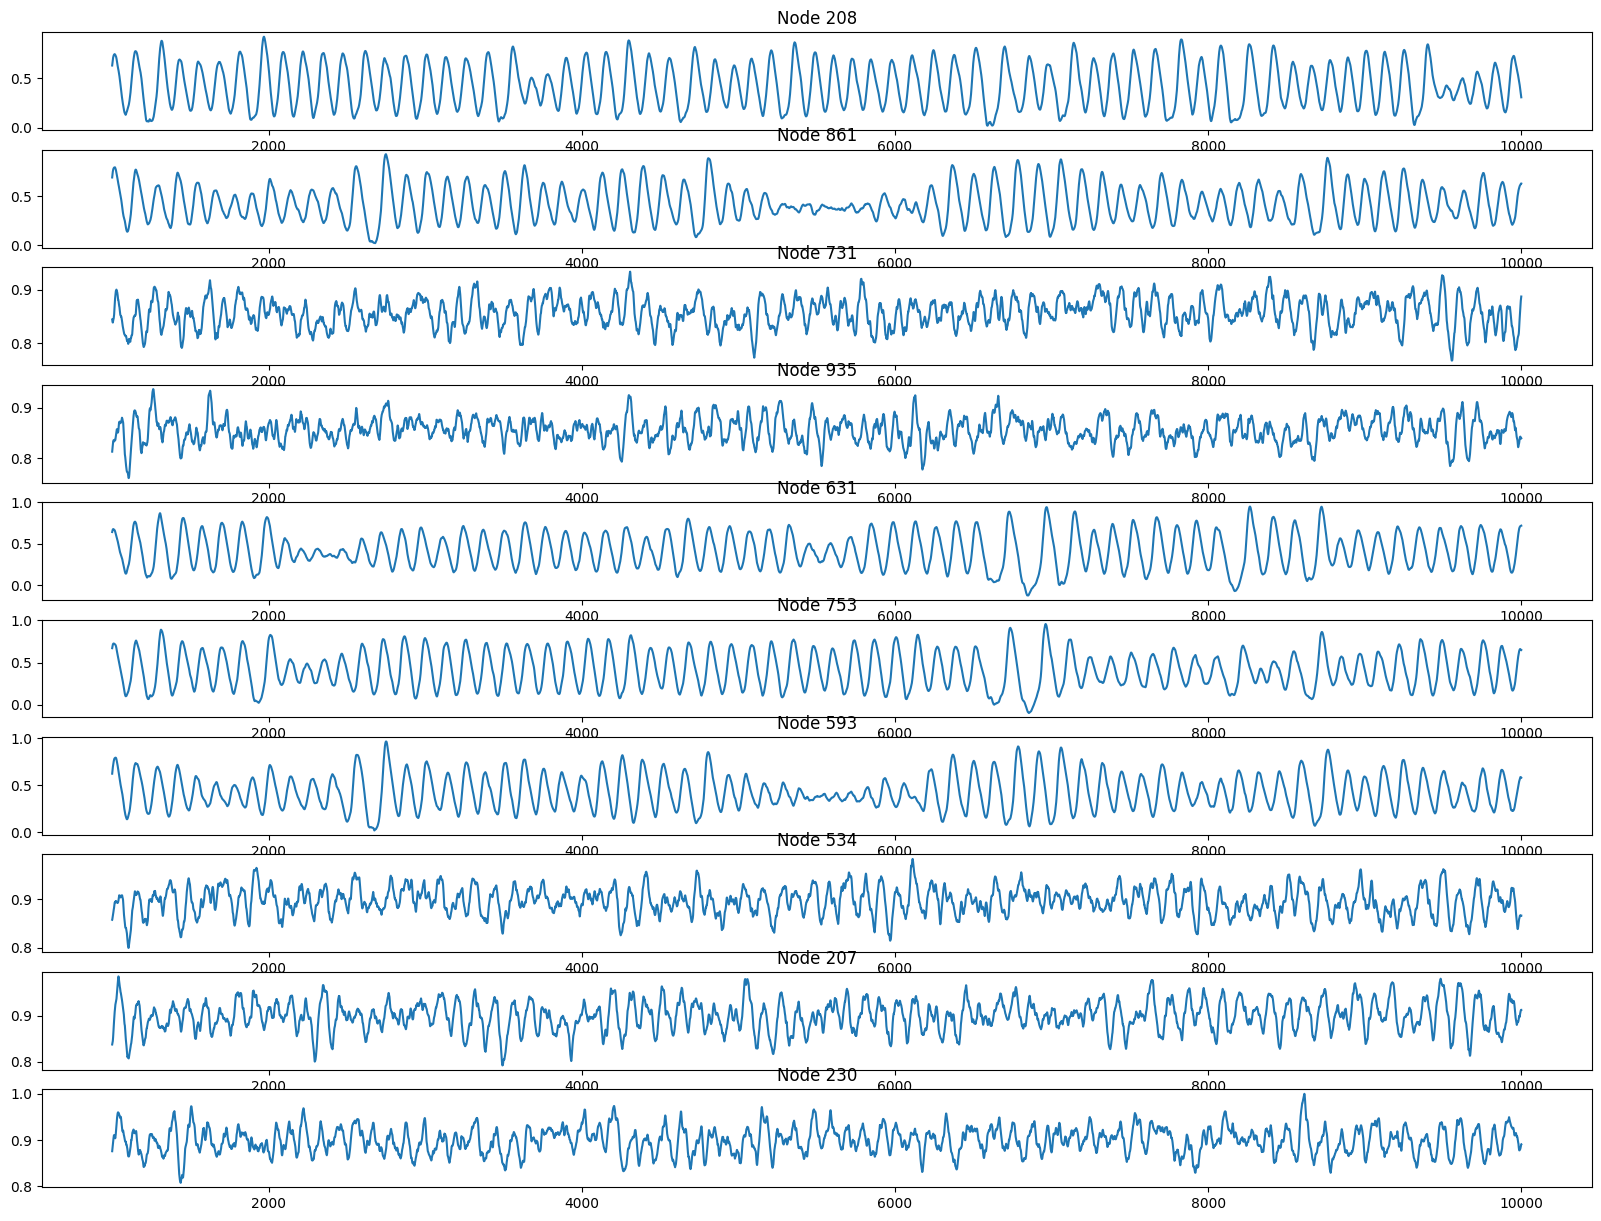

In [132]:
plot_activity(t, data)

In [131]:
plot_graph_activity(conn, t, data, range_=[4000, 6000])

Widget(value='<iframe src="http://localhost:40815/index.html?ui=P_0x78d702e6a650_30&reconnect=auto" class="pyv…